## BirdCLEF 2026 - data download

The cell below downloads the competition data from Kaggle, but only if it is not already in the `data/` folder. Complete these steps once before running it.

**1. Verify your Kaggle account**
1. Sign in (or create an account) at [kaggle.com](https://www.kaggle.com).
2. Go to **Settings → Phone verification, Identity verification** and verify yourself. Kaggle blocks competition data downloads for unverified accounts.

**2. Accept the competition rules**
1. Open the [BirdCLEF 2026 competition](https://www.kaggle.com/competitions/birdclef-2026).
2. Click **Join Competition** / **I Understand and Accept**.

**3. Create a Kaggle API token**
1. Go to **Settings → API** on kaggle.com and create a new token (it starts with `KGAT_`).
2. Copy it right away - Kaggle shows it only once. Never share it or commit it to git.

**4. Make the token available to the notebook**
The token must be stored under the name `KAGGLE_API_TOKEN`. Use one of these options:

**Option A - Colab secrets (when running in Google Colab)**
1. Click the key icon (**Secrets**) in the left sidebar.
2. Add a new secret named `KAGGLE_API_TOKEN` with your token as the value.
3. Switch on **Notebook access** for it.

**Option B - `.env` file (local, VS Code, or Colab)**
1. Copy `.env.example` to `.env` and set `KAGGLE_API_TOKEN=your_token_here`.
2. Running in Colab: upload the `.env` file to the Colab working directory (**Files** panel → upload, usually `/content`). It is lost when the session ends, so upload it again each session.

**5. Run the cell**
Run the next cell. It downloads and extracts the data (~16 GB, so make sure there is enough free disk space). If the data is already there, it only prints the path.

In [2]:
import os
import subprocess
import sys
from pathlib import Path

COMPETITION = "birdclef-2026"
KAGGLE_TOKEN = "KAGGLE_API_TOKEN"  # name of the Colab secret / .env variable
DATA_ROOT = Path.cwd() / "data"  # git-ignored; kagglehub stores its cache here

# Files and folders that must exist for the data to count as complete
REQUIRED = [
    "train.csv",
    "taxonomy.csv",
    "train_soundscapes_labels.csv",
    "train_audio",
    "train_soundscapes",
]


def is_complete(folder):
    return all((folder / name).exists() for name in REQUIRED)


def find_local_data():
    """Return the folder holding the competition files, or None."""
    for train_csv in DATA_ROOT.rglob("train.csv"):
        if is_complete(train_csv.parent):
            return train_csv.parent
    return None


def load_from_colab_secrets():
    """Read the token from Colab Secrets; return False outside Colab."""
    try:
        from google.colab import userdata
    except ImportError:
        return False

    try:
        value = userdata.get(KAGGLE_TOKEN)
    except Exception:  # secret not defined or notebook access off
        return True
    if value:
        os.environ[KAGGLE_TOKEN] = value.strip()
    return True


def load_from_env_file():
    """Read the token from the nearest .env file (current folder or a parent)."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        env_file = folder / ".env"
        if not env_file.is_file():
            continue
        for line in env_file.read_text(encoding="utf-8").splitlines():
            line = line.strip()
            if not line or line.startswith("#") or "=" not in line:
                continue
            key, value = line.split("=", 1)
            key = key.strip().removeprefix("export ").strip()
            value = value.strip().strip("\"'")
            if key == KAGGLE_TOKEN and value:
                os.environ[KAGGLE_TOKEN] = value
        print(f"Loaded .env from {env_file}")
        return True
    return False


DATA_DIR = find_local_data()

if DATA_DIR:
    print(f"Data already available: {DATA_DIR}")
else:
    print(f"Data not found in {DATA_ROOT}, downloading from Kaggle...")

    # Token: 1. Colab secrets, 2. .env file
    load_from_colab_secrets()
    if not os.environ.get(KAGGLE_TOKEN):
        load_from_env_file()
    if not os.environ.get(KAGGLE_TOKEN):
        raise EnvironmentError(
            f"{KAGGLE_TOKEN} not found. Add it as a Colab secret (notebook "
            f"access on) or to a .env file. Working directory: {Path.cwd()}"
        )

    # Keep the kagglehub cache inside the repo (must be set before the import).
    os.environ["KAGGLEHUB_CACHE"] = str(DATA_ROOT)

    try:
        import kagglehub
    except ImportError:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
            check=True,
        )
        import kagglehub

    # Authenticate explicitly with the token
    from kagglehub.config import set_kaggle_api_token

    set_kaggle_api_token(os.environ[KAGGLE_TOKEN])

    # Fails here with a clear error if the token is rejected.
    print("Authenticated as:", kagglehub.whoami()["username"])

    # The competition rules must be accepted on kaggle.com (same account).
    DATA_DIR = Path(kagglehub.competition_download(COMPETITION))
    print("Path to competition files:", DATA_DIR)

    if not is_complete(DATA_DIR):
        missing = [n for n in REQUIRED if not (DATA_DIR / n).exists()]
        raise FileNotFoundError(f"Download finished but missing: {missing}")

Data already available: m:\Bird-CLEF\BridCLEF-team-buzby\data\competitions\birdclef-2026


Read metadata of audio files

In [ ]:
import pandas as pd
from tinytag import TinyTag

train_audio_metadata_csv = DATA_DIR / "train_audio_metadata.csv"
train_soundscapes_metadata_csv = DATA_DIR / "train_soundscapes_metadata.csv"

# Filenames are stored relative to their audio folder with "/" separators
# (same form as train.csv), so the CSVs work on any machine / OS.

# List train audio files ("species/file.ogg")
train_audio_dir = DATA_DIR / "train_audio"
train_audio_files = sorted(p.relative_to(train_audio_dir).as_posix() for p in train_audio_dir.glob("*/*.ogg"))

# List soundscape files ("file.ogg")
train_soundscapes_dir = DATA_DIR / "train_soundscapes"
train_soundscapes_files = sorted(p.relative_to(train_soundscapes_dir).as_posix() for p in train_soundscapes_dir.glob("*.ogg"))


def get_audio_metadata(audio_dir: Path, files: list[str], csv_output: str | Path | None = None) -> pd.DataFrame:
    """Read metadata of `files` (paths relative to `audio_dir`)."""
    metadata_list = []
    for f in files:
        audio = TinyTag.get(audio_dir / f)
        metadata_list.append({
            "filename": f,
            "duration": audio.duration,
            "channels": audio.channels,
            "sample_rate": audio.samplerate,
            "bitrate": audio.bitrate
        })
    metadata_df = pd.DataFrame(metadata_list)
    if csv_output:
        metadata_df.to_csv(csv_output, index=False)
    return metadata_df


def to_relative(path, n_parts: int) -> str:
    """Keep the last `n_parts` components of a (possibly absolute, Windows or POSIX) path."""
    return "/".join(str(path).replace("\\", "/").split("/")[-n_parts:])


def load_audio_metadata(csv_path: Path, audio_dir: Path, files: list[str], n_parts: int) -> pd.DataFrame:
    """Load cached metadata (converting old absolute paths), or compute and cache it."""
    if not csv_path.exists():
        return get_audio_metadata(audio_dir, files, csv_path)
    df = pd.read_csv(csv_path)
    relative = df["filename"].map(lambda p: to_relative(p, n_parts))
    if not relative.equals(df["filename"]):
        df["filename"] = relative
        df.to_csv(csv_path, index=False)  # rewrite the cache with relative paths
        print(f"Converted absolute paths to relative in {csv_path.name}")
    return df


train_audio_metadata_df = load_audio_metadata(train_audio_metadata_csv, train_audio_dir, train_audio_files, n_parts=2)
train_audio_metadata_df.set_index("filename", inplace=True)

train_soundscapes_metadata_df = load_audio_metadata(train_soundscapes_metadata_csv, train_soundscapes_dir, train_soundscapes_files, n_parts=1)
train_soundscapes_metadata_df.set_index("filename", inplace=True)

print(train_audio_metadata_df.head())
print(train_soundscapes_metadata_df.head())

In [4]:
train_audio_unique_sample_rates = train_audio_metadata_df["sample_rate"].unique()
print(f"Train audio sample rates: {len(train_audio_unique_sample_rates)} unique values")
print(train_audio_unique_sample_rates)

train_soundscapes_unique_sample_rates = train_soundscapes_metadata_df["sample_rate"].unique()
print(f"Train soundscapes sample rates: {len(train_soundscapes_unique_sample_rates)} unique values")
print(train_soundscapes_unique_sample_rates)

train_audio_unique_durations = train_audio_metadata_df["duration"].unique()
print(f"Train audio durations: {len(train_audio_unique_durations)} unique values")
print(train_audio_unique_durations)

train_soundscapes_unique_durations = train_soundscapes_metadata_df["duration"].unique()
print(f"Train soundscapes durations: {len(train_soundscapes_unique_durations)} unique values")
print(train_soundscapes_unique_durations)

Train audio sample rates: 1 unique values
[32000]
Train soundscapes sample rates: 1 unique values
[32000]
Train audio durations: 16596 unique values
[28.392      18.024       0.288      ...  4.43240625 13.0694375
 16.96      ]
Train soundscapes durations: 1 unique values
[60.]


In [ ]:
# Drop train audio files with duration less than 2 seconds
# (relative paths like "species/file.ogg", same form as train.csv "filename")
train_audio_files = train_audio_metadata_df[train_audio_metadata_df['duration'] >= 2].index.tolist()


# Labels

In [ ]:
# Taxonomy
taxonomy_df = pd.read_csv(DATA_DIR / "taxonomy.csv")
print("\nTaxonomy dataframe:")
print(taxonomy_df.head())
# Read train CSV
train_audio_label_df = pd.read_csv(DATA_DIR / "train.csv")
print("\nTrain audio labels dataframe:")
print(train_audio_label_df.head())
print(f"\n Audio files before dropping short duration files: {len(train_audio_label_df)}")
mask = train_audio_label_df['filename'].isin(set(train_audio_files))
train_audio_label_df = train_audio_label_df[mask]
print(f"\n Audio files after dropping short duration files: {len(train_audio_label_df)}")
# Soundscape labels
soundscapes_df = pd.read_csv(DATA_DIR / "train_soundscapes_labels.csv")
print("\nSoundscape labels dataframe:")
print(soundscapes_df.head())

#Check if primary_label - scientific_name, common_name, and class_name mapping is consistent with taxonomy
# unique pairs from each side
tax_pairs   = taxonomy_df[["primary_label", "scientific_name", "common_name", "class_name"]].drop_duplicates()
train_pairs = train_audio_label_df[["primary_label", "scientific_name", "common_name", "class_name"]].drop_duplicates()
# outer merge with indicator shows pairs that exist on only one side
cmp = tax_pairs.merge(train_pairs, on=["primary_label", "scientific_name", "common_name", "class_name"],
                      how="outer", indicator=True)
merge_value_counts = cmp["_merge"].value_counts()
print("Taxonomy and train data have " + str(merge_value_counts["both"]) + " matching pairs.")
print("Taxonomy and train data have " + str(merge_value_counts["left_only"]) + " pairs only in taxonomy. (These species are not present in the train data.)")
only_in_train = merge_value_counts["right_only"]
print("Taxonomy and train data have " + str(only_in_train) + " pairs only in train data. (These species are not present in the taxonomy or there are inconsistent label-name pairings.)")
if only_in_train > 0:
    print("There might be inconsistent label-name pairings between taxonomy and train data. Here are the pairs that are only in train data:")
    print(cmp[cmp["_merge"] == "right_only"])

## Taxonomy

In [7]:
# Taxonomy
print("\nTaxonomy:")
print(f"\nTaxonomy has {len(taxonomy_df)} rows and {taxonomy_df['primary_label'].nunique()} unique primary labels.")
assert taxonomy_df['primary_label'].is_unique, "Primary labels in taxonomy.csv are not unique."
taxonomy_df.set_index('primary_label', inplace=True)
print(f"\nTaxonomy has {taxonomy_df['scientific_name'].nunique()} unique animal scientific names.")
assert taxonomy_df['scientific_name'].is_unique, "Scientific names in taxonomy.csv are not unique."
print(f"\nThe number of animals in the classes of taxonomy: ")
print(taxonomy_df['class_name'].value_counts())


Taxonomy:

Taxonomy has 234 rows and 234 unique primary labels.

Taxonomy has 234 unique animal scientific names.

The number of animals in the classes of taxonomy: 
class_name
Aves        162
Amphibia     35
Insecta      28
Mammalia      8
Reptilia      1
Name: count, dtype: int64


## Train audio labels

In [8]:
# Check if filenames are unique in the table
assert train_audio_label_df['filename'].is_unique, "Filenames in train.csv are not unique."
print("Train audio labels have unique filenames.")
#train_audio_label_df.set_index("filename", inplace=True)

# Number of species and recordings per class
print("\nNumber of species per class present in training audio data:")
s_c_pairs = train_audio_label_df[["primary_label", "common_name", "class_name"]]
print(s_c_pairs.drop_duplicates()['class_name'].value_counts())


# Samples per species
print("\nNumber of recordings per species in training audio data:")
samples_per_species = s_c_pairs.value_counts()
print(samples_per_species)

occurance_counts = {}
for row in train_audio_label_df.itertuples(index=False):
    primary_label = row.primary_label
    occurance_counts[primary_label] = occurance_counts.get(primary_label, 0) + 1

taxonomy_df["training_audio_files_count"] = taxonomy_df.index.map(
    lambda x: occurance_counts.get(x, 0)
)

# Min, max and average number of recordings per species in the
aves = s_c_pairs[s_c_pairs["class_name"] == "Aves"]
aves_values = aves.value_counts()
print("\nAves class statistics:")
print(f"Minimum recordings per species: {aves_values.min()}")
print(f"Maximum recordings per species: {aves_values.max()}")
print(f"Average recordings per species: {aves_values.mean():.2f}")
print(f"Median recordings per species: {aves_values.median()}")

Train audio labels have unique filenames.

Number of species per class present in training audio data:
class_name
Aves        162
Amphibia     32
Mammalia      8
Insecta       3
Reptilia      1
Name: count, dtype: int64

Number of recordings per species in training audio data:
primary_label  common_name                 class_name
yeofly1        Yellow-olive Flatbill       Aves          493
banana         Bananaquit                  Aves          491
soulap1        Southern Lapwing            Aves          491
fepowl         Ferruginous Pygmy Owl       Aves          490
bncfly         Brown-crested Flycatcher    Aves          488
                                                        ... 
116570         Southern Spectacled Caiman  Reptilia        1
209233         Feral Horse                 Mammalia        1
23150          Central Dwarf Frog          Amphibia        1
23724          Waxy Monkey Tree Frog       Amphibia        1
516975         Hooded Capuchin             Mammalia       

In [9]:
# Soundscape labels
soundscapes_df = pd.read_csv(DATA_DIR / "train_soundscapes_labels.csv").drop_duplicates()
print("\nSoundscape labels dataframe:")
print(soundscapes_df.head())

# Records per filenames in soundscape labels
records_per_filename = soundscapes_df['filename'].value_counts()
print("\nNumber of records per filename in soundscape labels:")
print(records_per_filename)

print("\nChecking for duplicate (filename, start, end) combinations in soundscape labels...")
if soundscapes_df.duplicated(subset=['filename', 'start', 'end']).any():
    print("Soundscape labels have duplicate (filename, start, end) combinations.")
else:
    print("Soundscape labels have unique (filename, start, end) combinations.")


Soundscape labels dataframe:
                                    filename     start       end  \
0  BC2026_Train_0039_S22_20211231_201500.ogg  00:00:00  00:00:05   
1  BC2026_Train_0039_S22_20211231_201500.ogg  00:00:05  00:00:10   
2  BC2026_Train_0039_S22_20211231_201500.ogg  00:00:10  00:00:15   
3  BC2026_Train_0039_S22_20211231_201500.ogg  00:00:15  00:00:20   
4  BC2026_Train_0039_S22_20211231_201500.ogg  00:00:20  00:00:25   

                    primary_label  
0  22961;23158;24321;517063;65380  
1  22961;23158;24321;517063;65380  
2  22961;23158;24321;517063;65380  
3  22961;23158;24321;517063;65380  
4  22961;23158;24321;517063;65380  

Number of records per filename in soundscape labels:
filename
BC2026_Train_0039_S22_20211231_201500.ogg    12
BC2026_Train_0019_S22_20211104_200000.ogg    12
BC2026_Train_0053_S22_20220211_204500.ogg    12
BC2026_Train_0047_S22_20220131_003000.ogg    12
BC2026_Train_0027_S22_20211129_014500.ogg    12
                                          

In [10]:
def soundscape_labels_to_list(labels):
    """Convert a string of labels to a list of labels."""
    if pd.isna(labels):
        return []
    return [label.strip() for label in labels.split(";")]

def count_soundscape_labels(label_count,labels):
    for label in soundscape_labels_to_list(labels):
        label_count[label] = label_count.get(label, 0) + 1
    return label_count

label_count = {} 
label_file_count = {}
for row in soundscapes_df.itertuples():
    count_soundscape_labels(label_count, row.primary_label)
    for label in soundscape_labels_to_list(row.primary_label):
        if label not in label_file_count:
            label_file_count[label] = set()
        label_file_count[label].add(row.filename)

# Count the number of labels and the number of unique soundscape files for each label in the taxonomy
taxonomy_df['soundscape_label_count'] = taxonomy_df.index.map(lambda x: label_count.get(x, 0))
taxonomy_df['soundscape_file_count'] = taxonomy_df.index.map(lambda x: len(label_file_count.get(x, set())))

# Count the soundscape files where species occur per class_name
soundscape_class_file_count = {}
for row in taxonomy_df.itertuples():
    soundscape_class_file_count[row.class_name] = soundscape_class_file_count.get(row.class_name, 0) + row.soundscape_file_count
print("\nNumber of soundscape files where species occur per class:")
for class_name, count in soundscape_class_file_count.items():
    print(f"{class_name}: {count}")


Number of soundscape files where species occur per class:
Insecta: 57
Reptilia: 8
Amphibia: 220
Mammalia: 10
Aves: 75


In [11]:
train_audio_label_df.set_index("filename", inplace=True)

## Train audio samples

In [ ]:
# Inspect a training audio file
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

sample_number = 1956  # Change this to inspect a different sample

sample_file = train_audio_files[sample_number]  # relative, same form as train.csv "filename"
sample_path = train_audio_dir / sample_file

# Metadata
print(f"File: {sample_file}")
print("\nMetadata:")
print(train_audio_metadata_df.loc[sample_file])

# Label
label_row = train_audio_label_df.loc[sample_file]
print(f"\nPrimary label: {label_row['primary_label']}")
print(f"Scientific name: {label_row['scientific_name']}")
print(f"Common name: {label_row['common_name']}")
print(f"Class name: {label_row['class_name']}")

# Load at native sample rate
y, sr = librosa.load(sample_path, sr=None)

# STFT (magnitude in dB)
n_fft, hop_length = 2048, 512
stft_db = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length)), ref=np.max)

# Mel spectrogram (power in dB)
mel_db = librosa.power_to_db(
    librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=128),
    ref=np.max,
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
img = librosa.display.specshow(stft_db, sr=sr, hop_length=hop_length, x_axis="time", y_axis="hz", ax=axes[0])
axes[0].set_title("STFT spectrogram (dB)")
fig.colorbar(img, ax=axes[0], format="%+2.0f dB")
img = librosa.display.specshow(mel_db, sr=sr, hop_length=hop_length, x_axis="time", y_axis="mel", ax=axes[1])
axes[1].set_title("Mel spectrogram (dB)")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
plt.tight_layout()
plt.show()


## Soundscape audio samples

File: BC2026_Train_0027_S22_20211129_014500.ogg

Labels per 5 s section:
00:00:00 - 00:00:05: ['1491113', '22967', '22973', '24279', '517063', '65380', 'trsowl']
00:00:05 - 00:00:10: ['1491113', '22967', '22973', '517063', '65380', 'trsowl']
00:00:10 - 00:00:15: ['1491113', '22967', '22973', '24279', '517063', '65380', '67252', 'trsowl']
00:00:15 - 00:00:20: ['1491113', '22967', '22973', '24279', '517063', '65380', '67252']
00:00:20 - 00:00:25: ['1491113', '22967', '22973', '517063', '65380', 'trsowl']
00:00:25 - 00:00:30: ['1491113', '22967', '22973', '517063', '65380', 'trsowl']
00:00:30 - 00:00:35: ['1491113', '22967', '22973', '517063', '65380']
00:00:35 - 00:00:40: ['1491113', '22967', '22973', '517063', '65380', 'trsowl']
00:00:40 - 00:00:45: ['1491113', '22967', '22973', '517063', '65380', 'trsowl']
00:00:45 - 00:00:50: ['1491113', '22967', '22973', '517063', '65380', 'trsowl']
00:00:50 - 00:00:55: ['1491113', '22967', '22973', '517063', '65380']
00:00:55 - 00:01:00: ['1491113',

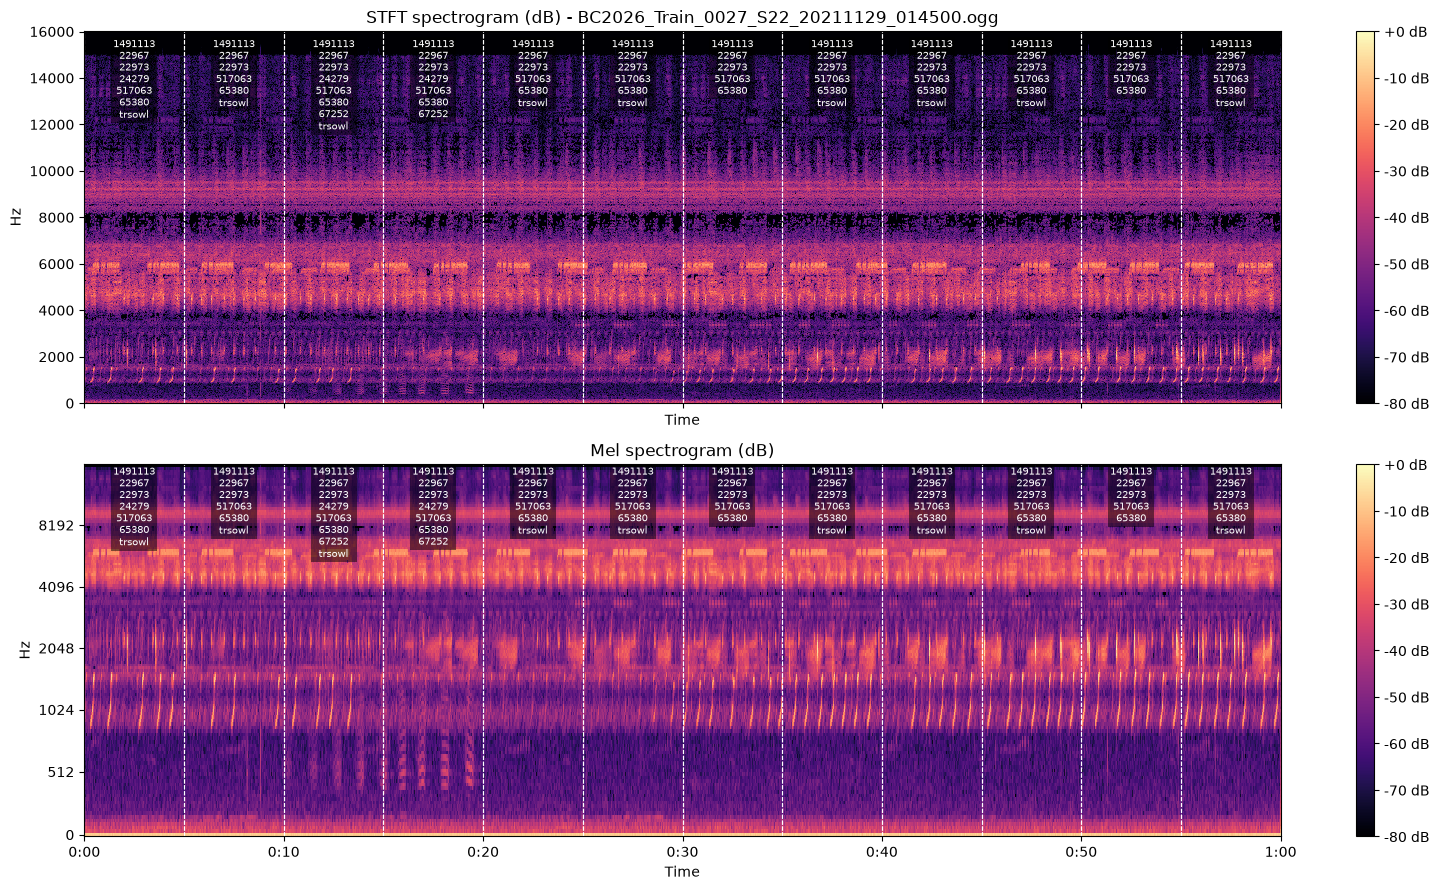

In [15]:
# Inspect one soundscape sample with its 5 s section labels
def time_to_seconds(t):
    """Convert 'HH:MM:SS' to seconds."""
    h, m, s = (int(x) for x in t.split(":"))
    return h * 3600 + m * 60 + s

sample_number = 56  # Change this to inspect a different soundscape sample
soundscape_file = soundscapes_df["filename"].iloc[sample_number]
soundscape_path = train_soundscapes_dir / soundscape_file
sections = soundscapes_df[soundscapes_df["filename"] == soundscape_file].sort_values("start")

print(f"File: {soundscape_file}")
print("\nLabels per 5 s section:")
legend = {}
for row in sections.itertuples():
    labels = soundscape_labels_to_list(row.primary_label)
    print(f"{row.start} - {row.end}: {labels}")
    for label in labels:
        legend[label] = taxonomy_df.loc[label, "common_name"] if label in taxonomy_df.index else "?"
print("\nLabel legend:")
for label, name in sorted(legend.items()):
    print(f"{label}: {name}")

# Load at native sample rate
y, sr = librosa.load(soundscape_path, sr=None)

n_fft, hop_length = 2048, 512
stft_db = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length)), ref=np.max)
mel_db = librosa.power_to_db(
    librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=128),
    ref=np.max,
)

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
img = librosa.display.specshow(stft_db, sr=sr, hop_length=hop_length, x_axis="time", y_axis="hz", ax=axes[0])
axes[0].set_title(f"STFT spectrogram (dB) - {soundscape_file}")
fig.colorbar(img, ax=axes[0], format="%+2.0f dB")
img = librosa.display.specshow(mel_db, sr=sr, hop_length=hop_length, x_axis="time", y_axis="mel", ax=axes[1])
axes[1].set_title("Mel spectrogram (dB)")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

# Mark section boundaries and write each section's labels (one per line) at its top
for ax in axes:
    ymax = ax.get_ylim()[1]
    for row in sections.itertuples():
        start, end = time_to_seconds(row.start), time_to_seconds(row.end)
        ax.axvline(start, color="white", linestyle="--", linewidth=0.8)
        ax.axvline(end, color="white", linestyle="--", linewidth=0.8)
        ax.text(
            (start + end) / 2, ymax * 0.98, "\n".join(soundscape_labels_to_list(row.primary_label)),
            ha="center", va="top", fontsize=7, color="white",
            bbox=dict(facecolor="black", alpha=0.5, pad=1.5, edgecolor="none"),
        )
plt.tight_layout()
plt.show()
